# Generating Synthetic Patients with a GAN on MIMIC-III

This notebook trains PyHealth's `GAN` to generate synthetic patients, each one a
set of diagnosis codes, from MIMIC-III data. It is a small example: training
takes under a minute on a CPU.

A GAN (Generative Adversarial Network; Goodfellow et al., 2014) trains two
networks against each other:

- the **generator** turns random noise into a fake patient;
- the **discriminator** looks at real and fake patients and learns to tell them
  apart.

Each network improves by beating the other: as the discriminator gets better at
spotting fakes, the generator has to produce more realistic patients to fool it.

**Data.** We use Synthetic MIMIC-III, a public, artificial copy of MIMIC-III
hosted by PyHealth, so no credentials are needed. It has the same table format
as the real database: to use your own MIMIC-III copy, change `root` in step 2.

## 1. Setup

In [1]:
import logging

import matplotlib.pyplot as plt
import pandas as pd
import torch

from pyhealth.datasets import MIMIC3Dataset, split_by_patient
from pyhealth.models import GAN
from pyhealth.tasks import EHRCodeSetGenerationMIMIC3

torch.manual_seed(42)
# Keep PyHealth's progress logging out of the way.
logging.getLogger("pyhealth").setLevel(logging.WARNING)

## 2. Load MIMIC-III

The GAN only needs the diagnoses table. The first run downloads it and caches
processed copies in `pyhealth_cache/`, which takes a few minutes; later runs
read the cache.

In [2]:
base_dataset = MIMIC3Dataset(
    root="https://storage.googleapis.com/pyhealth/Synthetic_MIMIC-III",
    tables=["diagnoses_icd"],
    cache_dir="pyhealth_cache",
)

## 3. Turn each patient into a set of codes

The `EHRCodeSetGenerationMIMIC3` task pools each patient's diagnosis codes from
all of their hospital admissions into one set, keeping patients with at least
two admissions.

Its `multi_hot` processor then turns each set into a vector with one slot per
code in the vocabulary: 1 if the patient has that code, 0 otherwise. These
vectors are what the GAN learns to generate.

In [3]:
samples = base_dataset.set_task(EHRCodeSetGenerationMIMIC3())

vocab = samples.input_processors["visits"].label_vocab
example = samples[0]["visits"]
print(f"Patients: {len(samples)}")
print(f"Distinct diagnosis codes: {len(vocab)}")
print(f"One patient: a vector of {example.shape[0]} slots, {int(example.sum())} set to 1")

  0%|          | 0/49993 [00:00<?, ?it/s]


Rank 0 inferred the following `['bytes']` data format.


  0%|          | 0/2085 [00:00<?, ?it/s]


Rank 0 inferred the following `['no_header_tensor:1', 'bytes']` data format.


100%|██████████| 2085/2085 [00:00<00:00, 6195.63it/s]


Patients: 2085
Distinct diagnosis codes: 2886
One patient: a vector of 2886 slots, 16 set to 1


## 4. Split by patient

We train on 80% of patients and keep 10% aside as held-out real patients to
compare the synthetic ones against. The GAN has no validation step, so the
middle 10% is unused here.

In [4]:
train_dataset, _, test_dataset = split_by_patient(samples, [0.8, 0.1, 0.1], seed=42)
print(f"Training patients: {len(train_dataset)}")
print(f"Held-out patients: {len(test_dataset)}")

Training patients: 1668
Held-out patients: 209


## 5. Build the GAN

Passing a dataset puts `GAN` in code-set mode: the generator and discriminator
are small fully connected networks sized to the code vocabulary. `hidden_dim` is
both the size of the random noise the generator starts from and the width of
the hidden layers.

In [5]:
model = GAN(dataset=samples, hidden_dim=128)
print(model.generator)
print(model.discriminator)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Sequential(
  (0): Linear(in_features=128, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=2886, bias=True)
  (5): Sigmoid()
)
Sequential(
  (0): Linear(in_features=2886, out_features=128, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): LeakyReLU(negative_slope=0.2)
  (4): Linear(in_features=128, out_features=1, bias=True)
  (5): Sigmoid()
)
Parameters: 791,495


## 6. Train

For every batch of real patients, `train_model` takes two steps:

1. **Discriminator step:** show it the real batch and an equal batch of fakes,
   and nudge it to label real as real and fake as fake.
2. **Generator step:** nudge the generator so the discriminator labels its
   fakes as real.

PyHealth's `Trainer` does not apply here, because the two networks have
opposing goals and need separate optimizers; `train_model` runs that loop. We
train for 30 epochs (passes over the training patients).

In [6]:
history = model.train_model(train_dataset, epochs=30, batch_size=64)

GAN training: 100%|██████████| 30/30 [00:25<00:00,  1.17it/s]


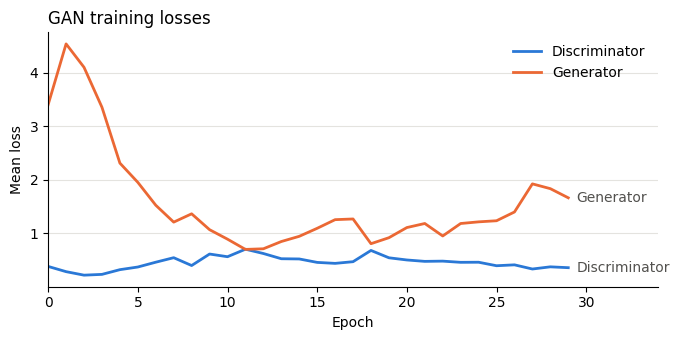

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
series = [
    ("d_loss", "Discriminator", "#2a78d6"),
    ("g_loss", "Generator", "#eb6834"),
]
for key, label, color in series:
    ax.plot(history[key], color=color, linewidth=2, label=label)
    ax.annotate(
        label,
        xy=(len(history[key]) - 1, history[key][-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color="#52514e",
    )
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean loss")
ax.set_title("GAN training losses", loc="left")
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
ax.set_xlim(0, len(history["d_loss"]) + 4)
plt.tight_layout()
plt.show()

Unlike a classifier's loss, these curves do not both settle downward: each
network's progress shows up as the other's loss rising. Ups and downs are
normal.

Longer training is not automatically better. If the discriminator's loss drops
toward 0, it has won outright, and the generator typically collapses to
producing nearly identical patients ("mode collapse"). A short run is enough for
this example.

## 7. Generate synthetic patients

The generator gives every code a probability. `generate` turns those into code
sets; with `random_sampling=True` it flips a weighted coin per code. The
default, keeping codes at or above 0.5, would rarely include uncommon codes, so
most synthetic patients would look alike.

In [8]:
synthetic = model.generate(num_samples=1000, random_sampling=True)

for patient in synthetic[:3]:
    codes = patient["visits"][0]
    print(f"{patient['patient_id']}: {len(codes)} codes, e.g. {codes[:6]}")

synthetic_0: 20 codes, e.g. ['2762', '2875', '29181', '30560', '4019', '4160']
synthetic_1: 21 codes, e.g. ['2765', '29181', '30560', '4019', '41091', '41410']
synthetic_2: 25 codes, e.g. ['1173', '1580', '2851', '2875', '30560', '30981']


## 8. Compare with real patients

Two quick checks against the held-out real patients:

- **How many codes does a patient have?**
- **Are common real codes also common in synthetic patients?** For each of the
  most frequent real codes, compare the share of real and synthetic patients
  who have it, and correlate those shares across the whole vocabulary.

In [9]:
processor = samples.input_processors["visits"]
real = torch.stack([test_dataset[i]["visits"] for i in range(len(test_dataset))])
fake = torch.stack([processor.process(p["visits"][0]) for p in synthetic])

print(f"Codes per patient: real {real.sum(1).mean():.1f}, synthetic {fake.sum(1).mean():.1f}")

real_share = real.mean(0)
fake_share = fake.mean(0)
correlation = torch.corrcoef(torch.stack([real_share, fake_share]))[0, 1]
print(f"Correlation of per-code shares across all codes: {correlation:.2f}")

index_to_code = {index: code for code, index in vocab.items()}
top = real_share.topk(10).indices.tolist()
pd.DataFrame(
    {
        "ICD-9 code": [index_to_code[i] for i in top],
        "Real patients": [f"{real_share[i]:.0%}" for i in top],
        "Synthetic patients": [f"{fake_share[i]:.0%}" for i in top],
    }
)

Codes per patient: real 16.7, synthetic 19.5
Correlation of per-code shares across all codes: 0.44


,ICD-9 code,Real patients,Synthetic patients
0,4019,49%,99%
1,4280,35%,92%
2,25000,34%,6%
3,41401,31%,3%
4,42731,31%,4%
5,53081,21%,7%
6,2449,20%,1%
7,5990,19%,76%
8,5849,18%,1%
9,51881,17%,7%


The GAN gets the overall shape roughly right, with a similar number of codes
per patient, but not the details: a few common codes appear in almost every
synthetic patient, while others that are common among real patients are rare.
Over-producing a handful of patterns like this is typical of a small GAN
trained briefly.

## Summary

We loaded MIMIC-III diagnoses, turned each patient into a set of codes, trained
a GAN for 30 epochs, and generated synthetic patients whose code counts and
common codes can be compared with real ones.

This is a minimal example rather than a strong generator: the networks are
small, training is short, and the source data is itself synthetic. For a GAN
designed specifically for synthetic patient records, see `MedGAN` and
`examples/medgan_mimic3.py`.